In [1]:
# conda env 'vis2'

import sys
import os
sys.path.append('/data/keeling/a/johntl3/b/LundstromPub2025/src')

from util import load_sensor_dict
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import glob
import at3d

from collections import defaultdict

In [2]:
def parse_at3d_output(dir):
    loss_file = dir + '/loss.csv'
    log_file = dir + '/at3d.log'
    info = {}
    try:
        with open(log_file, 'r') as file:
            lines = list(file)
            info['termination'] = lines[-1].strip()
            info['F'] = float(lines[-3].split()[2])
            info['N'] = int(lines[-4].split()[0])
            info['Tit'] = int(lines[-4].split()[1])
            info['Tnf'] = int(lines[-4].split()[2])
            info['Tnint'] =  int(lines[-4].split()[3])
            info['Skip'] = int(lines[-4].split()[4])
            info['Nact'] = int(lines[-4].split()[5])
            info['Projg'] = float(lines[-4].split()[6].replace('D','E'))
            info['max_cell_splitting'] = False
            for l in lines:
                if('Further cell splitting' in l):
                    info['max_cell_splitting'] = True
                if('Execution time' in l):
                    info['run time'] = float(l.split()[2])
    except FileNotFoundError:
        print('Error: File not found at {}'.format(log_file))
    except Exception as e:
        print(f"Error while parsing log file: {e}")

    try:
        with open(loss_file, 'r') as file:
            lines = list(file)
            info['total_obj_fn_time'] = float(lines[-1].split()[2])
    except FileNotFoundError:
        print('Error: File not found at {}'.format(loss_file))
    except Exception as e:
        print(f"Error while parsing log file: {e}")
    
    return info

In [3]:
def load_retreival(dir):
    assert os.path.isdir(dir + '/iterations/')
    name = os.path.split(dir)[-1]
    files = np.sort(glob.glob(dir + '/iterations/iter*.nc'))
    sensors, solvers, rte_grid = at3d.util.load_forward_model(files[-1])
    data = parse_at3d_output(dir)
    data['files'] = files
    data['sensors'] = sensors
    data['solvers'] = solvers
    data['rte_grid'] = rte_grid
    return data

In [4]:
def traverse(dir, data, parent_key=()):
    name = os.path.split(dir)[-1]
    parent_key += (name,)
    if(os.path.isdir(dir + '/iterations/')):
        data[parent_key] = load_retreival(dir)
    else:
        for n in os.listdir(dir):
            traverse(dir+'/'+n, data, parent_key)


In [5]:
version_dir = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/AT3D_output/V03'
data = defaultdict(defaultdict)
traverse(version_dir, data)

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '68'. Max cell optical depth: '3.3179593086242676'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3

In [6]:
def calc_error_metrics(reference, data):
    if('solvers' in list(data.keys())):
        ext_tmp = np.ravel(data['solvers'][0.67].medium['cloud'].extinction.data)
        ext_ref = np.ravel(reference['solvers'][0.67].medium['cloud'].extinction.data)
        data['relative difference'] = 100 * (np.sum((ext_tmp - ext_ref)**2))**0.5 / (np.sum(ext_ref)**2)**0.5
        data['relative bias'] = 100 * (np.sum(np.abs(ext_tmp)) - np.sum(np.abs(ext_ref))) / (np.sum(np.abs(ext_ref)))
        data['MAE'] = np.sum(np.abs(ext_tmp - ext_ref)) / len(ext_tmp)
        data['RMSE'] = (np.sum((ext_tmp - ext_ref)**2) / len(ext_tmp))**0.5
        data['r'] = (np.sum((ext_tmp - np.mean(ext_tmp)) * (ext_ref - np.mean(ext_ref)))) / ((np.sum((ext_tmp - np.mean(ext_tmp))**2)**0.5) * (np.sum((ext_ref - np.mean(ext_ref))**2)**0.5))
        data['NMB'] = np.sum(ext_tmp - ext_ref) / np.sum(ext_ref)

        tmp = data['solvers'][0.67].medium['cloud'].copy(deep=True)
        mask = (tmp.extinction.data > 0).astype(np.int64)
        tmp['cvm'] = (['x', 'y', 'z'], mask)
        cv = tmp.cvm.integrate(['x','y','z']).data
        tmp_ref = reference['solvers'][0.67].medium['cloud'].copy(deep=True)
        mask = (tmp_ref.extinction.data > 0).astype(np.int64)
        tmp_ref['cvm'] = (['x', 'y', 'z'], mask)
        cv_ref = tmp_ref.cvm.integrate(['x','y','z']).data
        data['cloud volume'] = cv
        data['delta volume'] = cv - cv_ref

        tmp['tau'] = tmp.extinction.integrate(['z'])
        tmp['cloud_mask'] = (tmp.tau > 0).astype(np.int64)
        tmp['cf'] = tmp.cloud_mask.sum() / (tmp.sizes['x'] * tmp.sizes['y'])
        data['cloud fraction'] = tmp.cf.data
        data['tau bar'] = tmp.tau.where(tmp.cloud_mask > 0).mean().data
    else:
        for n in data:
            calc_error_metrics(reference, data[n])

In [7]:
reference = data[('V03', 'default')]
calc_error_metrics(reference, data)

In [8]:
print('{:<49} | {:<5} | {:<4} | {:<6} | {:<6} | {:<7} | {:<6} | {:<14} | {:<20} '.format(
    'Path',
    'N',
    'Tit',
    't (s)',
    's/iter',
    '% SHDOM',
    'F',
    'Max Cell Split',
    'Termination'
))
print('-'*170)
for k, v in data.items():
    print('{:<49} | {:<5d} | {:<4d} | {:<6.0f} | {:<6.1f} | {:<7.2f} | {:<6.2f} | {:<14} | {:<20} '.format(
        str(k),
        v['N'],
        v['Tit'],
        v['run time'],
        v['run time']/v['Tit'],
        100 - 100*v['total_obj_fn_time']/v['run time'],
        v['F'],
        v['max_cell_splitting'],
        v['termination']
    ))

Path                                              | N     | Tit  | t (s)  | s/iter | % SHDOM | F      | Max Cell Split | Termination          
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------
('V03', 'default')                                | 11587 | 22   | 14451  | 656.9  | 0.39    | 647.16 | 0              | CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH 
('V03', 'aerosol', '0p250')                       | 11587 | 18   | 7347   | 408.2  | 0.46    | 601.31 | 0              | CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH 
('V03', 'aerosol', 'mix22')                       | 11587 | 15   | 4951   | 330.1  | 0.58    | 654.64 | 0              | CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH 
('V03', 'aerosol', 'mix54')                       | 11587 | 20   | 6359   | 317.9  | 0.55    | 612.59 | 0              | CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH 
('V03'

In [18]:
df = pd.DataFrame.from_dict(data).T
df['rate'] = df['run time'] / df['Tit']
df['shdom_time'] = df['run time'] - df['total_obj_fn_time']
df['obj_fn_calls_per_iter'] = df['Tnf'] / df['Tit']

<Axes: xlabel='N', ylabel='rate'>

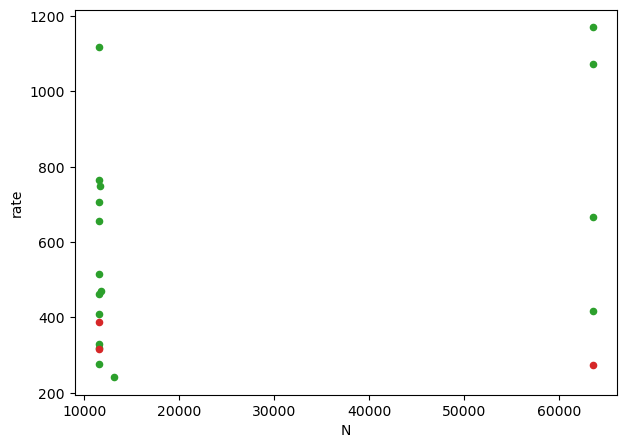

In [22]:
xvar = 'N'
yvar = 'rate'
df_sub = df[df['Tit'] > 1]
f, ax = plt.subplots(1, 1, figsize=(7,5))
df_sub[df_sub['termination'] != 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:green', ax=ax)
df_sub[df_sub['termination'] == 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:red', ax=ax)


<Axes: xlabel='Tit', ylabel='run time'>

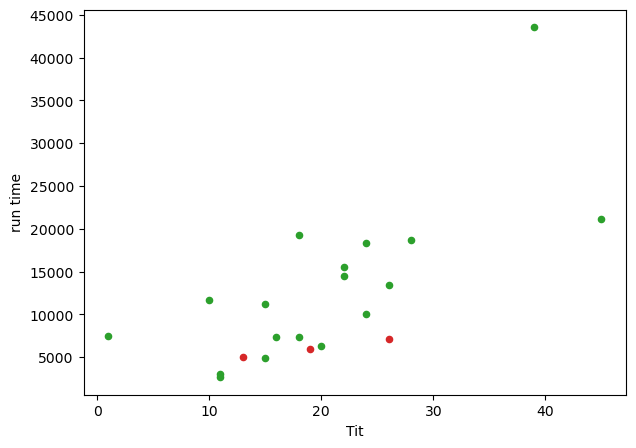

In [11]:
xvar = 'Tit'
yvar = 'run time'
# df_sub = df[df['Tit'] > 1]
df_sub = df
f, ax = plt.subplots(1, 1, figsize=(7,5))
df_sub[df_sub['termination'] != 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:green', ax=ax)
df_sub[df_sub['termination'] == 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:red', ax=ax)


<Axes: xlabel='Tit', ylabel='shdom_time'>

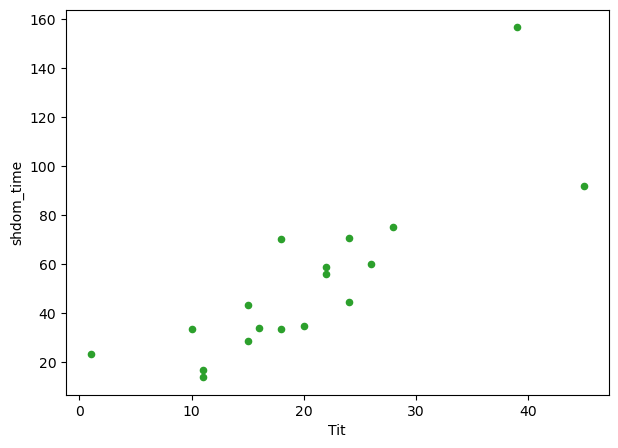

In [14]:
xvar = 'Tit'
yvar = 'shdom_time'
# df_sub = df[df['Tit'] > 1]
df_sub = df
f, ax = plt.subplots(1, 1, figsize=(7,5))
df_sub[df_sub['termination'] != 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:green', ax=ax)
# df_sub[df_sub['termination'] == 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:red', ax=ax)


<Axes: xlabel='Tit', ylabel='total_obj_fn_time'>

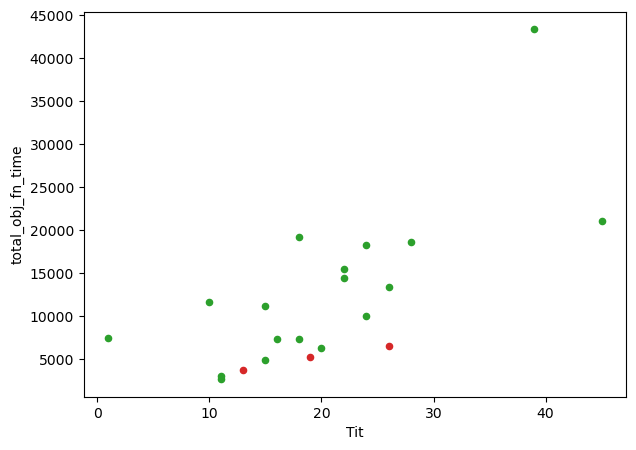

In [13]:
xvar = 'Tit'
yvar = 'total_obj_fn_time'
# df_sub = df[df['Tit'] > 1]
df_sub = df
f, ax = plt.subplots(1, 1, figsize=(7,5))
df_sub[df_sub['termination'] != 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:green', ax=ax)
df_sub[df_sub['termination'] == 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:red', ax=ax)


<Axes: xlabel='relative bias', ylabel='run time'>

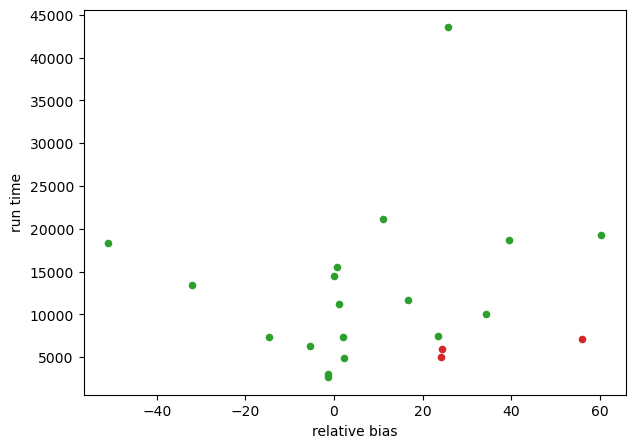

In [15]:
xvar = 'relative bias'
yvar = 'run time'
# df_sub = df[df['Tit'] > 1]
df_sub = df
f, ax = plt.subplots(1, 1, figsize=(7,5))
df_sub[df_sub['termination'] != 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:green', ax=ax)
df_sub[df_sub['termination'] == 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:red', ax=ax)


<Axes: xlabel='relative bias', ylabel='shdom_time'>

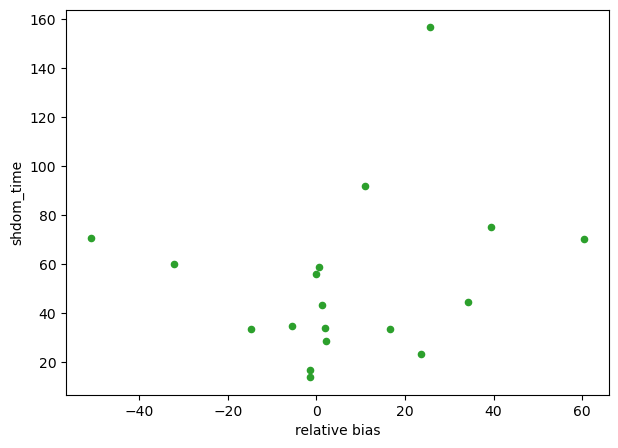

In [17]:
xvar = 'relative bias'
yvar = 'shdom_time'
# df_sub = df[df['Tit'] > 1]
df_sub = df
f, ax = plt.subplots(1, 1, figsize=(7,5))
df_sub[df_sub['termination'] != 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:green', ax=ax)
# df_sub[df_sub['termination'] == 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:red', ax=ax)


<Axes: xlabel='obj_fn_calls_per_iter', ylabel='run time'>

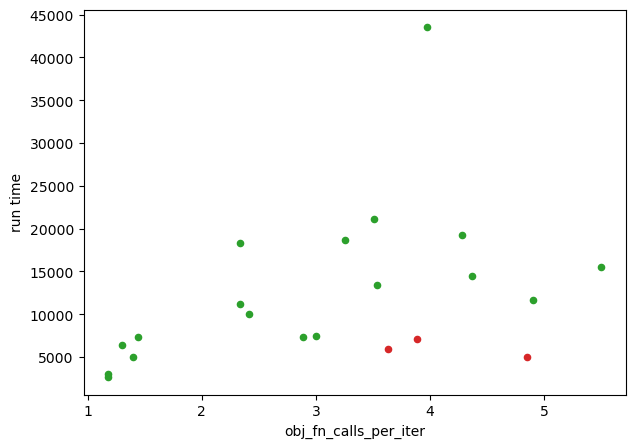

In [19]:
xvar = 'obj_fn_calls_per_iter'
yvar = 'run time'
# df_sub = df[df['Tit'] > 1]
df_sub = df
f, ax = plt.subplots(1, 1, figsize=(7,5))
df_sub[df_sub['termination'] != 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:green', ax=ax)
df_sub[df_sub['termination'] == 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:red', ax=ax)


<Axes: xlabel='Tnf', ylabel='run time'>

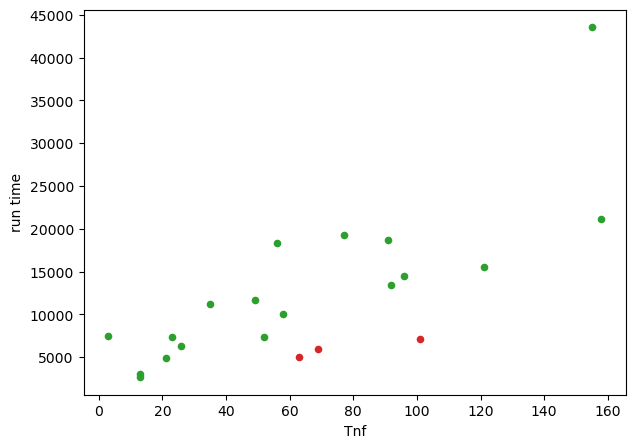

In [20]:
xvar = 'Tnf'
yvar = 'run time'
# df_sub = df[df['Tit'] > 1]
df_sub = df
f, ax = plt.subplots(1, 1, figsize=(7,5))
df_sub[df_sub['termination'] != 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:green', ax=ax)
df_sub[df_sub['termination'] == 'ABNORMAL_TERMINATION_IN_LNSRCH'].plot.scatter(x=xvar, y=yvar, c='tab:red', ax=ax)
